# Red Wine Quality Dataset

## Introduction

The origins of wine can be traced back to 6000 BC from the country of Georgia. In 2022, wine consumption worldwide was estimated to amount to 232 million hectoliters (https://www.statista.com/statistics/232937/volume-of-global-wine-consumption/). This is dataset about red wine, which is made from dark-colored grape varieties. The red color of the wine is coming from anthocyan pigments present in the skin of the grape. Much of the red wine production process involves extraction of color and flavor components from the grape skin (https://en.wikipedia.org/wiki/Red_wine). 

**Dataset information**

This is dataset taken from kaggle (https://www.kaggle.com/datasets/uciml/red-wine-quality-cortez-et-al-2009?resource=download).

The two datasets are related to red and white variants of the Portuguese "Vinho Verde" wine. For more details, consult the reference [Cortez et al., 2009]. Due to privacy and logistic issues, only physicochemical (inputs) and sensory (the output) variables are available (e.g. there is no data about grape types, wine brand, wine selling price, etc.).

These datasets can be viewed as classification or regression tasks. The classes are ordered and not balanced (e.g. there are much more normal wines than excellent or poor ones).

**Vinho Verde** is not a grape variety, it is a DOC (denominação de origem controlada, the system of protected designation of origin from Portugal) for the production of wine. The name means "green wine," but translates as "young wine", with wine being released three to six months after the grapes are harvested. Majority of Vinho Verde wines are wine but they also also produce rose and red wines. The Vinho Verde red wines usually have red color and a fruity flavor with the tasting notes of pepper, peony, and sour plum. (Source: https://en.wikipedia.org/wiki/Vinho_Verde)

**Project**

Red Wine Quality dataset is used for Statistical Modeling project of Data Analysis module sprint 3. Data analysis is done using python and pandas library. For visualization matplotlib and seaborn libraries were used. The project is done using Jupyter notebooks (4.0.6).

The project is done using python (version 3.11.4), seaborn (0.12.2), matplotlib (3.8.0), pandas (2.0.3), sklearn (1.3.0), statsmodels (0.14.1) and scipy (1.11.2) libraries.

**Plan**

First, I will do exploratory data analysis, look into wine features.

Second, I will look into three questions: 
* Do chloride levels differ between depending on wine quality?
* Do alcohol levels differ between quality 5 and 6 wines?
* Does pH differ between quality 4 and 7 wines?
And I will try to answer them using hypothesis testing.

Third, I will create few models:
* To predict wine quality using features in the dataset, using logistic regression for classification;
* Linear regression model to predict alcohol content in the wine using rest of the features.

**Dashboard**

This is a link to my created dashboard for this project:
https://lookerstudio.google.com/u/0/reporting/c062b7be-afee-4c1e-9b63-f9c92a4c4645

# Preparation

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib as plt
import statsmodels.api as sm
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
from sklearn.model_selection import train_test_split
from scipy import stats
from scripts import *

In [2]:
data = pd.read_csv('data/winequality-red.csv')
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


## Checking for nulls and duplicates

In [3]:
data.isnull().any()

fixed acidity           False
volatile acidity        False
citric acid             False
residual sugar          False
chlorides               False
free sulfur dioxide     False
total sulfur dioxide    False
density                 False
pH                      False
sulphates               False
alcohol                 False
quality                 False
dtype: bool

In [4]:
data.columns.duplicated().any()

False

In [5]:
data.duplicated().any()

True

In [6]:
data.drop_duplicates(inplace=True)
data.duplicated().any()

False

# Exploratory data analysis

In [7]:
shape = data.shape
shape

(1359, 12)

In [8]:
data.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
dtype: object

In [9]:
data.describe()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
count,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000,1359.000000
mean,8.310596,0.529478,0.272333,2.523400,0.088124,15.893304,46.825975,0.996709,3.309787,0.658705,10.432315,5.623252
std,1.736990,0.183031,0.195537,1.352314,0.049377,10.447270,33.408946,0.001869,0.155036,0.170667,1.082065,0.823578
min,4.600000,0.120000,0.000000,0.900000,0.012000,1.000000,6.000000,0.990070,2.740000,0.330000,8.400000,3.000000
25%,7.100000,0.390000,0.090000,1.900000,0.070000,7.000000,22.000000,0.995600,3.210000,0.550000,9.500000,5.000000
50%,7.900000,0.520000,0.260000,2.200000,0.079000,14.000000,38.000000,0.996700,3.310000,0.620000,10.200000,6.000000
75%,9.200000,0.640000,0.430000,2.600000,0.091000,21.000000,63.000000,0.997820,3.400000,0.730000,11.100000,6.000000
max,15.900000,1.580000,1.000000,15.500000,0.611000,72.000000,289.000000,1.003690,4.010000,2.000000,14.900000,8.000000


There does not seem to be any outliers which would be "imposible" values in this dataset. Nontheless, we can check how many features have outliers in them and how many of them there are.

In [10]:
outliers = outlier_f(data)
outliers.count(axis=0)

fixed acidity            41
volatile acidity         19
citric acid               1
residual sugar          126
chlorides                87
free sulfur dioxide      26
total sulfur dioxide     45
density                  35
pH                       28
sulphates                55
alcohol                  12
quality                  27
dtype: int64

In [11]:
print(f'In total there are {outliers.count(axis = 0).sum()} outlier values.')

In total there are 502 outlier values.


In [12]:
outliers_lower = outlier_f(data, lower=True)
outliers_lower.count(axis=0)

fixed acidity            0
volatile acidity         0
citric acid              0
residual sugar           0
chlorides                4
free sulfur dioxide      0
total sulfur dioxide     0
density                 18
pH                      11
sulphates                0
alcohol                  0
quality                 10
dtype: int64

In [13]:
outliers_upper = outlier_f(data, upper=True)
outliers_upper.count(axis=0)

fixed acidity            41
volatile acidity         19
citric acid               1
residual sugar          126
chlorides                83
free sulfur dioxide      26
total sulfur dioxide     45
density                  17
pH                       17
sulphates                55
alcohol                  12
quality                  17
dtype: int64

In [14]:
for i in range(1, outliers.count(axis=1).max() + 1):
    temp = 0
    for row in outliers.count(axis=1):
        if row == i:
            temp += 1
    print(f'{temp} {"wine has" if temp == 1 else "wines have"} {i} outlier {"feature" if i == 1 else "features"}.')

245 wines have 1 outlier feature.
79 wines have 2 outlier features.
21 wines have 3 outlier features.
9 wines have 4 outlier features.


In [15]:
out_index = outliers.dropna(axis=0, how='all').index
print(f'In total there are {len(out_index)} wines with outlier features')

In total there are 354 wines with outlier features


In [16]:
mask = data.index.isin(out_index)
data_noout = data.loc[~mask]
data_noout.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4,5


Created a dataset with no outliers to use for modeling later on. Going to compare how well clasification works with outlier wines and without them.

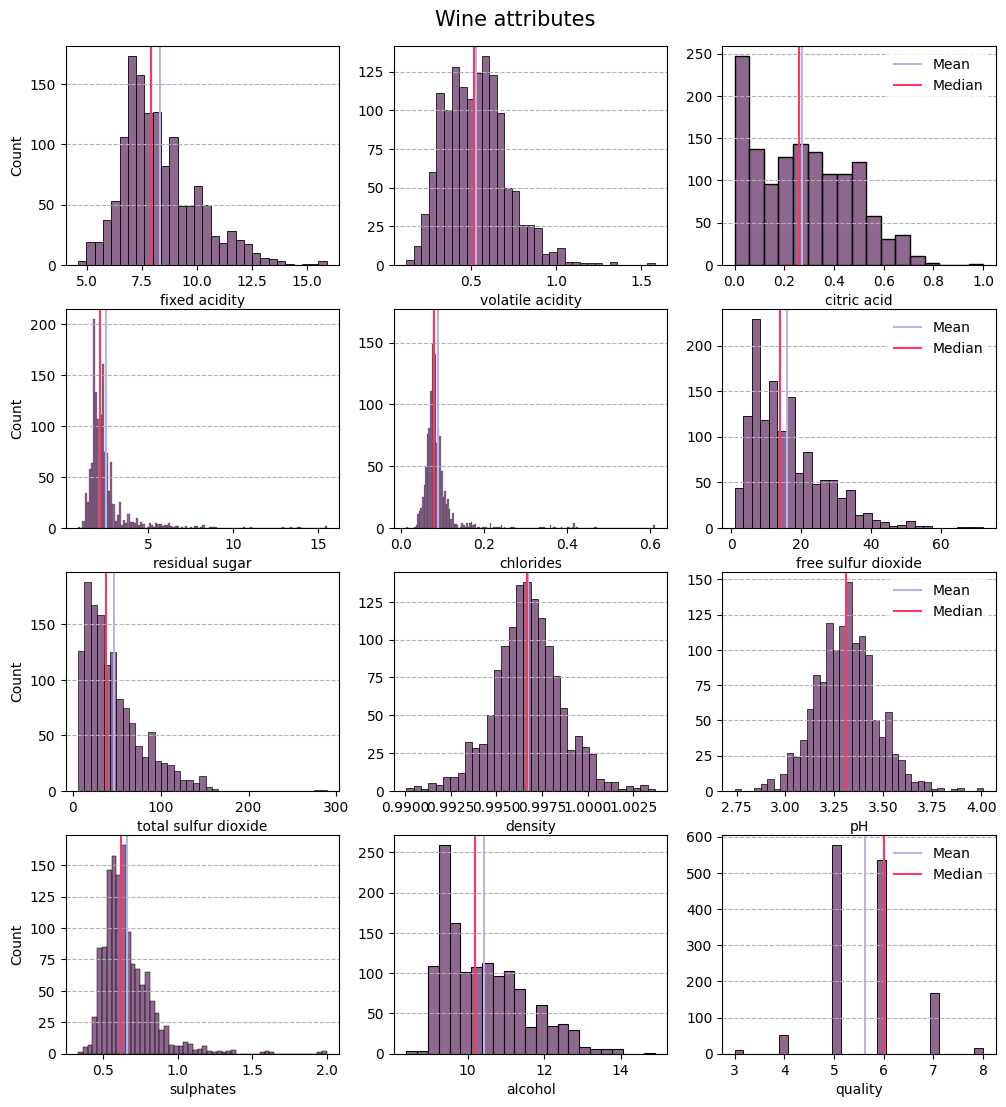

In [17]:
fig, axs = plt.pyplot.subplots(4, 3, figsize=(12, 12))
fig.suptitle('Wine attributes', fontsize=15)
fig.subplots_adjust(top=0.95)

i = 0
j = 0
for col in range(shape[1]):
    ax = histplot_f(data.iloc[:, col], color='#693668', color_median='#FF3562', ax=axs[j, i])

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    # Leaving only right most legends
    if i == 2:
        pass
    else:
        ax.get_legend().set_visible(False)

    i += 1
    if i == 3:
        i = 0
        j += 1

plt.pyplot.tight_layout;

Most of attributes are distributed normaly or approximately normaly. All of distributions are skewed to the right, except for density, pH and quality.

In [18]:
correlation = data.corr().stack()

# Removing of unnesessary "self-correlation" values:
correlation = correlation[correlation.index.get_level_values(0) != correlation.index.get_level_values(1)]
correlation = correlation.unstack()

correlation.style.background_gradient(cmap=sns.color_palette("ch:s=-.2,r=.6", as_cmap=True), axis=None)

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,nan,-0.255124,0.667437,0.111025,0.085886,-0.140580,-0.103777,0.670195,-0.686685,0.190269,-0.061596,0.119024
volatile acidity,-0.255124,nan,-0.551248,-0.002449,0.055154,-0.020945,0.071701,0.023943,0.247111,-0.256948,-0.197812,-0.395214
citric acid,0.667437,-0.551248,nan,0.143892,0.210195,-0.048004,0.047358,0.357962,-0.550310,0.326062,0.105108,0.228057
residual sugar,0.111025,-0.002449,0.143892,nan,0.026656,0.160527,0.201038,0.324522,-0.083143,-0.011837,0.063281,0.013640
chlorides,0.085886,0.055154,0.210195,0.026656,nan,0.000749,0.045773,0.193592,-0.270893,0.394557,-0.223824,-0.130988
free sulfur dioxide,-0.140580,-0.020945,-0.048004,0.160527,0.000749,nan,0.667246,-0.018071,0.056631,0.054126,-0.080125,-0.050463
total sulfur dioxide,-0.103777,0.071701,0.047358,0.201038,0.045773,0.667246,nan,0.078141,-0.079257,0.035291,-0.217829,-0.177855
density,0.670195,0.023943,0.357962,0.324522,0.193592,-0.018071,0.078141,nan,-0.355617,0.146036,-0.504995,-0.184252
pH,-0.686685,0.247111,-0.550310,-0.083143,-0.270893,0.056631,-0.079257,-0.355617,nan,-0.214134,0.213418,-0.055245
sulphates,0.190269,-0.256948,0.326062,-0.011837,0.394557,0.054126,0.035291,0.146036,-0.214134,nan,0.091621,0.248835


Highest correlations are between fixed acidity with citric acid and density - they positively correlated. Total sulfur dioxide and free sulfur dioxide are also positively correlated. pH is negatively correlated with fixed acidity and citric acid. Volatile acidity is negatively correlated with citric acid, and alcohol is negatively correlated with density. Rest of correlations are from medium to low.

Alcohol features in this dataset:

- fixed acidity – it corresponds to the set of low volatility organic acids such as malic, lactic, tartaric or citric acids and is inherent to the characteristics of the sample.
- volatile acidity – it corresponds to the set of short chain organic acids that can be extracted from the sample by means of a distillation process: formic acid, acetic acid, propionic acid and butyric acid. Acetic acid makes up 99% of this feature, therefore often only it is measured to determine volatile acidity.
- citric acid – it is naturally occurring within fresh grapes, but only minimally as perhaps 5% of a grapes total acidity, unless it is added. Citric acid is first degraded to acetic acid and pyruvic acid.
  - This explains why fixed acidity correlated positively with citric acid and volatile acidity has slight negative correlation - citric acid degrades to acetic acid which is part of volatile acidity.
- residual sugar – natural grape sugars leftover in a wine after the alcoholic fermentation finishes.
- chlorides – contributes to wine saltyness. Moderate to large concentrations of chlorides and sodium can give the wine salty taste which is undesirable. *Terroir* (vineyard's unique combination of climate, topography and soil) and grape variety do have an influence over the concentration of chloride in red wines.
- free sulfur dioxide – Wines are made out of grape juice, yeast and sulfur dioxide (SO2). SO2 is added to preserve wine’s freshness and fruit characters by virtue of antioxidant, antimicrobial and anti-enzymatic properties. SO2 that is present in wine but has not yet reacted is considered “free.”
- total sulfur dioxide – Total Sulfur Dioxide (TSO2) is the portion of SO2 that is free in the wine plus the portion that is bound to other chemicals in the wine such as aldehydes, pigments, or sugars. Therefore, it is positively correlated with free sulfur dioxide.
- density – it is an important physical property of all liquids, defined as the mass of a substance per unit of volume. It affects wine's mouthfeel. Tartaric acid was found to increase density the most, followed by glucose and glycerol, whereas ethanol decreased density. Therefore, density positively correlates with fixed acidity and negatively correlates with alcohol levels in wine.
- pH – a figure expressing the acidity or alkalinity of a solution on a logarithmic scale on which 7 is neutral, lower values are more acid and higher values more alkaline. Wine typically has pH level from 3 to 4 making it fairly acidic. Lower the pH the more acidic the wine, therefore it is negatively correlated with citric acid and fixed acidity. It seems that volatile acidity has higher pH than fixed acidity and citric acid, therefore it correlates slightly positively with pH.
- sulphates – they are salts of sulfuric acid. 
- alcohol – a colourless volatile flammable liquid which is produced by the natural fermentation of sugars. In drinks it is ethanol (ethyl alcohol). 
- quality – Wine quality often is defined in incredibly diverse ways. It may be evaluated in terms of subtlety and complexity, aging potential, stylistic purity, varietal expression, ranking by experts, or consumer acceptance. Wine quality strongly depends on the grape quality. It is necessary to process healthy grapes at the correct ripeness stage. It assures the right fermentation process. Higher content of sugars in grapes, means that yeasts are able to make more alcohol. Therefore, this might explain why higher alcohol levels correlate with quality of wine.

Sources: 
https://wineserver.ucdavis.edu/industry-info/enology/methods-and-techniques/common-chemical-reagents/citric-acid
https://sinatech.info/en/acetic-volatile-acidity-in-wine-cider-vinegars-and-juices/
https://www.scielo.br/j/cta/a/HQsrPrPMNZYgRzSKtrjHyHh/?format=pdf
https://winefolly.com/deep-dive/what-is-residual-sugar-in-wine/
https://www.wineshopathome.com/understanding-sulfur-levels-wine/
https://www.extension.iastate.edu/wine/total-sulfur-dioxide-why-it-matters-too/
https://www.researchgate.net/publication/361815237_Correlation_of_Wine%27s_Main_Components%27_Concentration_with_the_Density_of_Model_Aqueous_Solutions_and_Wine_Samples
https://www.wineenthusiast.com/basics/advanced-studies/what-is-acidity-in-wine/
https://www.winespectator.com/articles/difference-between-sulfites-sulfates-wine-54706
https://www.sciencedirect.com/topics/food-science/wine-quality

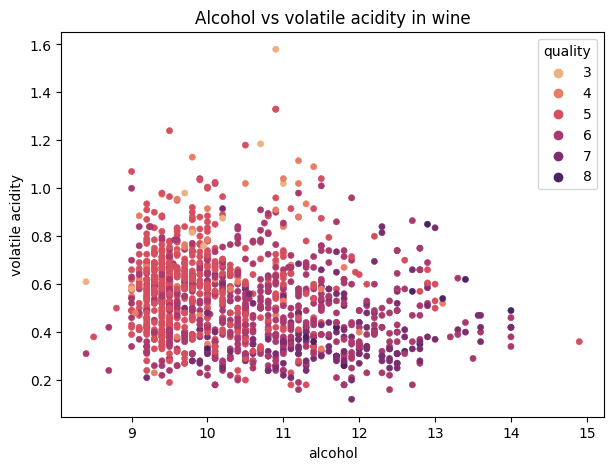

In [19]:
fig = plt.pyplot.figure(figsize=(7, 5))

ax = sns.scatterplot(data=data, x='alcohol', y='volatile acidity', hue='quality', palette='flare', s=20, edgecolor=None)
ax.set(title='Alcohol vs volatile acidity in wine');

Volatile acidity does not seem to correlated with alcohol in any way. We can see a slight tendency for higher quality wines to have higher alcohol content and lower volatile acidity. However, there are no clear groups in this chart.

# Hyphotesis testing

After exploring the data, there are several questions, in which we can look into:

- Do chloride levels differ between depending on wine quality?
- Do alcohol levels differ between quality 5 and 6 wines?
- Does pH differ between quality 4 and 7 wines?

We can try to answer these questions using the data. Hypothesis testing will be applied to check if there is any statistical significance. $ H_0 $ will always be that there is no difference, and $ H_1 $ accordingly will be that there is a difference. Chosen significance level – $ α $ will be 5% (or 0.05). Since there are few hypotheses Bonferroni Correction will be used: $ α $ is going to be divided by the number of hyphoteses made – 3 (which results to roughly 0.0167).

## Chloride levels depending on wine quality

To compare chloride levels between different wine qualities one way ANOVA test will be used. One way Anova test compares the difference between groups means. The test itself cannot tell where the difference is, only that there is a difference between the groups.

$ H_0 $ will be that there is no difference between chloride levels in different groups. $ H_1 $ accordingly will be that there is a difference. 

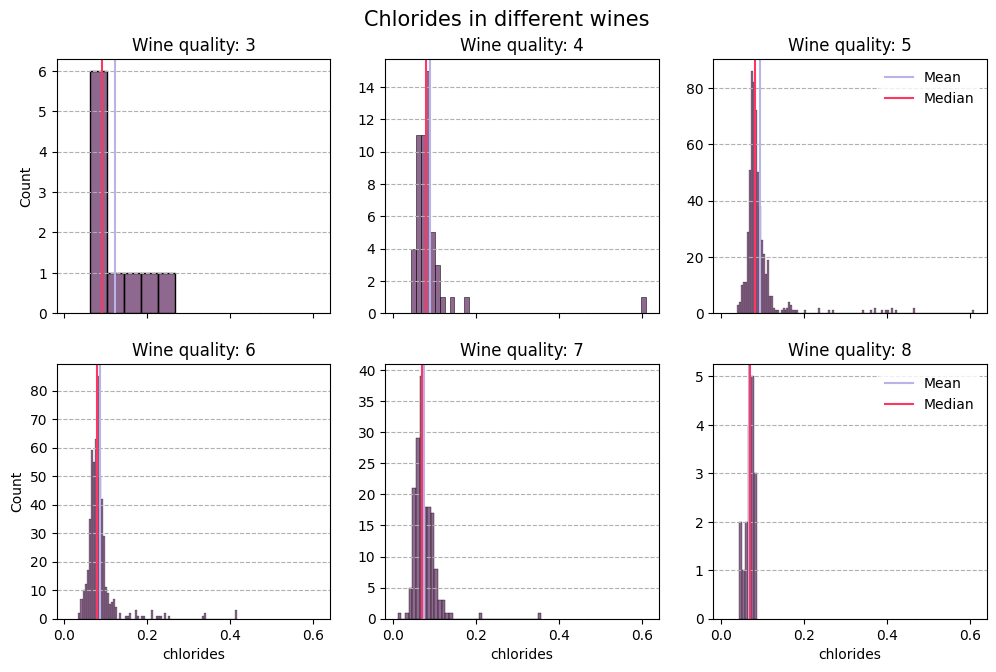

In [20]:
fig, axs = plt.pyplot.subplots(2, 3, sharex=True, figsize=(12, 7))
fig.suptitle('Chlorides in different wines', fontsize=15)
fig.subplots_adjust(top=0.91)

i = 0
j = 0
qualities = sorted(data.quality.unique())

for quality in qualities:
    mask = data.quality == quality
    ax = histplot_f(data.loc[:, 'chlorides'][mask], color='#693668', color_median='#FF3562', ax=axs[j, i])
    ax.set(title=f'Wine quality: {quality}')

    # Leaving only left most labels for y
    if i == 0:
        pass
    else:
        ax.set(ylabel='')

    # Leaving only right most legends
    if i == 2:
        pass
    else:
        ax.get_legend().set_visible(False)

    i += 1
    if i == 3:
        i = 0
        j += 1

plt.pyplot.tight_layout;

Distributions for different wines are approximately normal and are skewed to the right.

Since we have a lot of observations we can also apply central limit theorem and test hypothesis. Also one way ANOVA is robust and tolerate data that is non-normal. We also have to assume that there is homogeneity of variances and independence of observations.

In [21]:
stats.f_oneway(
    data['chlorides'][data['quality'] == 3],
    data['chlorides'][data['quality'] == 4],
    data['chlorides'][data['quality'] == 5],
    data['chlorides'][data['quality'] == 6],
    data['chlorides'][data['quality'] == 7],
    data['chlorides'][data['quality'] == 8],
)

F_onewayResult(statistic=5.401692657177557, pvalue=6.317934182391986e-05)

The p value is lower than set significance level (0.0167), therefore there is a statistical significant difference between groups.

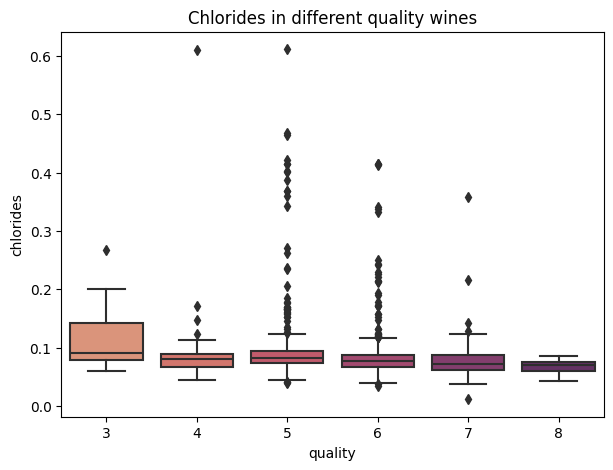

In [22]:
fig = plt.pyplot.figure(figsize=(7, 5))

ax = sns.boxplot(data=data, x='quality', y='chlorides', palette='flare')
ax.set(title='Chlorides in different quality wines');

We can see some diffrences in chloride levels between different quality wines. However, the differences are small.

Tukey's honestly significant difference (HSD) was used as post hoc test to see which groups differ from which.

In [23]:
res = stats.tukey_hsd(
    data['chlorides'][data['quality'] == 3],
    data['chlorides'][data['quality'] == 4],
    data['chlorides'][data['quality'] == 5],
    data['chlorides'][data['quality'] == 6],
    data['chlorides'][data['quality'] == 7],
    data['chlorides'][data['quality'] == 8],
)
print(res)

Tukey's HSD Pairwise Group Comparisons (95.0% Confidence Interval)
Comparison  Statistic  p-value  Lower CI  Upper CI
 (0 - 1)      0.032     0.412    -0.016     0.080
 (0 - 2)      0.029     0.449    -0.016     0.073
 (0 - 3)      0.037     0.159    -0.007     0.082
 (0 - 4)      0.046     0.049     0.000     0.091
 (0 - 5)      0.054     0.062    -0.002     0.110
 (1 - 0)     -0.032     0.412    -0.080     0.016
 (1 - 2)     -0.003     0.997    -0.023     0.017
 (1 - 3)      0.006     0.968    -0.015     0.026
 (1 - 4)      0.014     0.471    -0.008     0.036
 (1 - 5)      0.022     0.575    -0.017     0.061
 (2 - 0)     -0.029     0.449    -0.073     0.016
 (2 - 1)      0.003     0.997    -0.017     0.023
 (2 - 3)      0.009     0.030     0.001     0.017
 (2 - 4)      0.017     0.001     0.005     0.029
 (2 - 5)      0.026     0.275    -0.009     0.060
 (3 - 0)     -0.037     0.159    -0.082     0.007
 (3 - 1)     -0.006     0.968    -0.026     0.015
 (3 - 2)     -0.009     0.030   

We can see that there is no statistically significant difference between most of groups (since we take our significance level as 0.0167). The only statistically different groups are quality 7 and quality 5 wines (need to add 3 to comparison column, as qualities are from 3 to 8 and the the groups in the comparison are from 0 to 5).

## Alcohol levels in quality 5 and 6 wines

Is there different alcohol levels between quality 5 and 6 wines? 

$ H_0 $ will be that there is no difference between alcohol levels of quality 5 and quality 6 wines. $ H_1 $ will be that there is a difference. 

In [24]:
mask = data.quality == 5
q_5 = data.alcohol[mask]
q_5.describe()

count    577.000000
mean       9.888562
std        0.749930
min        8.500000
25%        9.400000
50%        9.600000
75%       10.200000
max       14.900000
Name: alcohol, dtype: float64

In [25]:
mask = data.quality == 6
q_6 = data.alcohol[mask]
q_6.describe()

count    535.000000
mean      10.658879
std        1.054933
min        8.400000
25%        9.800000
50%       10.500000
75%       11.400000
max       14.000000
Name: alcohol, dtype: float64

Means are different and higher quality wine has higher alcohol level on average (9.9 for quality 5 compared to 10.66 for quality 6).

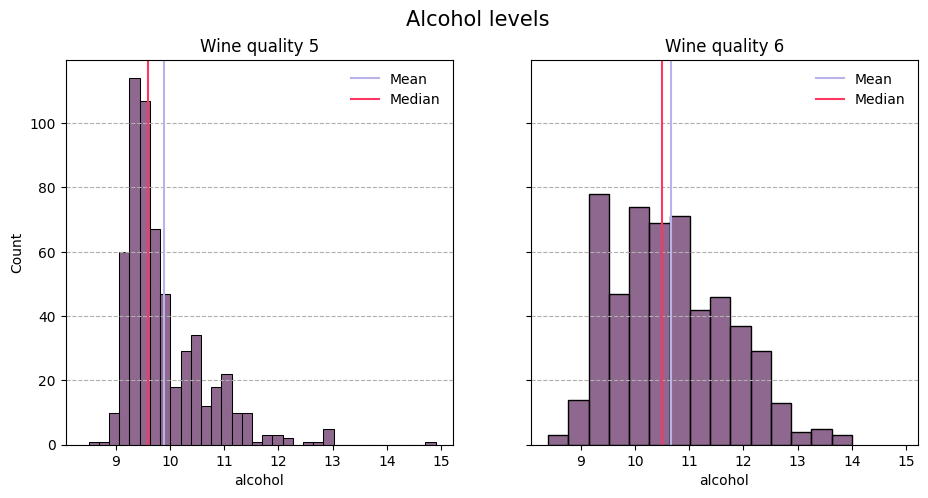

In [26]:
fig, axs = plt.pyplot.subplots(1, 2, sharex=True, sharey=True, figsize=(11, 5))
fig.suptitle('Alcohol levels', fontsize=15)


ax1 = histplot_f(q_5, color='#693668', color_median='#FF3562', ax=axs[0])
ax1.set(title='Wine quality 5')

ax1 = histplot_f(q_6, color='#693668', color_median='#FF3562', ax=axs[1])
ax1.set(title='Wine quality 6');

We can see that both distributions are approximatelly normal and somewhat skewed to the right.

Since there are a lot of datapoints, we can apply Central limit theorem, and test hypothesis using t-test.

In [27]:
stats.ttest_ind(q_5, q_6)

TtestResult(statistic=-14.111401900760644, pvalue=1.0338522497681734e-41, df=1110.0)

In [28]:
conf_int_q_5 = stats.t.interval(0.95, df=len(q_5) - 1, loc=q_5.mean(), scale=q_5.sem())
conf_int_q_5

(9.827242615715749, 9.949880434544218)

In [29]:
conf_int_q_6 = stats.t.interval(0.95, df=len(q_6) - 1, loc=q_6.mean(), scale=q_6.sem())
conf_int_q_6

(10.56928397467088, 10.748473034674914)

We can see that there is a statistical difference between average alcohol levels using t-test and the confidence interavals do not overlap.

In addition we can check Mood’s median test and Mann-Whitney U test to check if this result holds up.

In [30]:
stats.mannwhitneyu(q_5, q_6)

MannwhitneyuResult(statistic=83291.0, pvalue=2.466404450328332e-40)

In [31]:
stats.median_test(q_5, q_6)

MedianTestResult(statistic=151.62996481420376, pvalue=7.633094185673292e-35, median=10.0, table=array([[170, 356],
       [407, 179]], dtype=int64))

Non-parametric tests (Mood’s median and Mann-Whitney U) also give low p value. Therefore, we can reject the null hypothesis and can say that there is a statistically significant difference between quality 5 and quality 6 wine's alcohol levels. The alcohol level in quality 6 wines tends to be higher.

## Difference in ph of quality 4 and 7 wines

Is there a difference between pH in quality 4 and 7 wines? 

$ H_0 $ will be that there is no difference between the groups. $ H_1 $ correspondingly will be that there is a difference. 

In [32]:
mask = data.quality == 4
q_4 = data.pH[mask]
q_4.describe()

count    53.000000
mean      3.381509
std       0.181441
min       2.740000
25%       3.300000
50%       3.370000
75%       3.500000
max       3.900000
Name: pH, dtype: float64

In [33]:
mask = data.quality == 7
q_7 = data.pH[mask]
q_7.describe()

count    167.000000
mean       3.290060
std        0.149233
min        2.920000
25%        3.200000
50%        3.280000
75%        3.370000
max        3.780000
Name: pH, dtype: float64

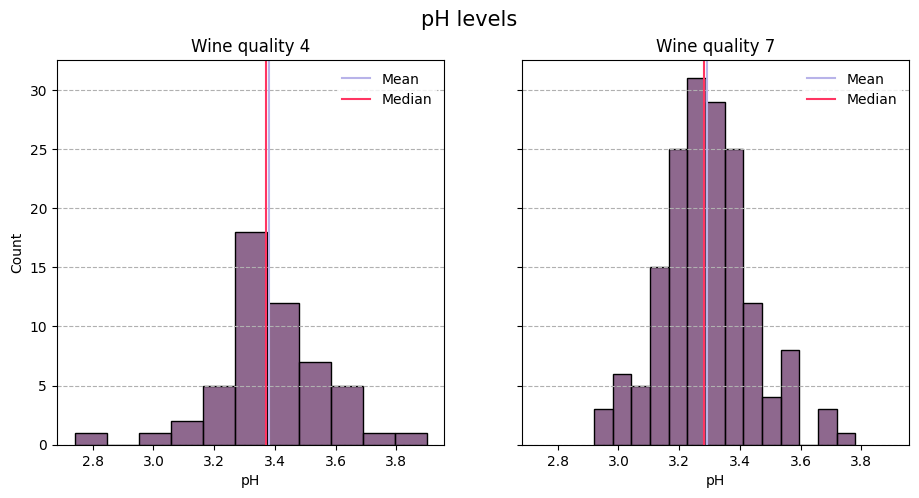

In [34]:
fig, axs = plt.pyplot.subplots(1, 2, sharex=True, sharey=True, figsize=(11, 5))
fig.suptitle('pH levels', fontsize=15)


ax1 = histplot_f(q_4, color='#693668', color_median='#FF3562', ax=axs[0])
ax1.set(title='Wine quality 4')

ax1 = histplot_f(q_7, color='#693668', color_median='#FF3562', ax=axs[1])
ax1.set(title='Wine quality 7');

Both distributions are approximatelly normal. We can see that quality 4 wine tends to be slightly less acidic compared to quality 7 wine.

Once again we are going to build confidence levels and test the differences using t-test, Moods median test and Mann-Whitney U test.

In [35]:
conf_int_q_4 = stats.t.interval(0.95, df=len(q_4) - 1, loc=q_4.mean(), scale=q_4.sem())
conf_int_q_4

(3.3314981627034492, 3.431520705221079)

In [36]:
conf_int_q_7 = stats.t.interval(0.95, df=len(q_7) - 1, loc=q_7.mean(), scale=q_7.sem())
conf_int_q_7

(3.2672600092992004, 3.312859751179842)

In [37]:
stats.ttest_ind(q_4, q_7)

TtestResult(statistic=3.6825195660761985, pvalue=0.00029124303670161945, df=218.0)

In [38]:
stats.mannwhitneyu(q_4, q_7)

MannwhitneyuResult(statistic=6039.5, pvalue=6.398243512412575e-05)

In [39]:
stats.median_test(q_4, q_7)

MedianTestResult(statistic=12.030279064512486, pvalue=0.000523432390425787, median=3.3049999999999997, table=array([[38, 72],
       [15, 95]], dtype=int64))

The confidence intervals are close, but the p values for all 3 tests are lower than set significance level (0.0167). We can reject the null hyphotesis and say that there is statistical difference between pH levels in quality 4 and 7 wines.

# Modeling

Last part is using modeling to predict wine quality and alcohol levels in the wine.

## Model to predict premium wine

Logistic regression is used to classify wines into different qualities. In this case, the wines will be classified into two groups: premium –  quality 7 or 8, or not – lower quality wine.

### Model 1

In [40]:
x = data.iloc[:, :-1]
x.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,9.4


Splitting the data into "premium" (quality 7, 8) and "other" (quality 3, 4, 5, 6) wines 

In [41]:
y = data.quality.map({3: 0, 4: 0, 5: 0, 6: 0, 7: 1, 8: 1})
y.value_counts()

quality
0    1175
1     184
Name: count, dtype: int64

In [42]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=0, stratify=data["quality"])

In [43]:
log_reg = sm.Logit(y_train, x_train).fit()

Optimization terminated successfully.
         Current function value: 0.278877
         Iterations 8


In [44]:
log_reg.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                quality   No. Observations:                 1087
Model:                          Logit   Df Residuals:                     1076
Method:                           MLE   Df Model:                           10
Date:                Tue, 23 Jan 2024   Pseudo R-squ.:                  0.2992
Time:                        22:45:04   Log-Likelihood:                -303.14
converged:                       True   LL-Null:                       -432.54
Covariance Type:            nonrobust   LLR p-value:                 7.639e-50
========================================================================================
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
fixed acidity            0.0376      0.101      0.372      0.710      -0.160       0.235
volatile acidity        -4.0478      0.948     -4.270      0.000      -5.906      -2.190
citric acid             -0.0501      1.021     -0.049      0.961      -2.052       1.952
residual sugar           0.1679      0.079      2.138      0.033       0.014       0.322
chlorides               -8.3851      3.985     -2.104      0.035     -16.195      -0.575
free sulfur dioxide      0.0011      0.015      0.076      0.940      -0.027       0.030
total sulfur dioxide    -0.0108      0.005     -1.987      0.047      -0.021      -0.000
density                 -9.3863      4.161     -2.256      0.024     -17.542      -1.230
pH                      -0.6741      1.057     -0.638      0.524      -2.746       1.398
sulphates                3.5342      0.622      5.683      0.000       2.315       4.753
alcohol                  0.8751      0.107      8.178      0.000       0.665       1.085
========================================================================================
"""

If we take significance level as 0.05, we can see that fixed acidity, citric acid, free sulfur dioxide and pH are higher, and not that important in determining if wine is premium quality or not. Total sulful dioxide also is on the line, as p value is close to 0.05. 

In [45]:
log_reg.pred_table()

array([[908.,  31.],
       [104.,  44.]])

In the training set, we have 908 true positives (ordinary wines clasified as ordinary) and 31 false positives (ordinary wines clasified as premium). There are 104 false negatives (premium wines clasified as ordinary) and 44 true negatives (premium wines clasified as premium). 

In [46]:
yhat = log_reg.predict(x_test)
prediction = list(map(round, yhat))

In [47]:
cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix : \n", cm)

Confusion Matrix : 
 [[232   4]
 [ 22  14]]


Same logic applies to the test set, and here we have 246 wines classfied correctly out of 272.

In [48]:
print(f'Test accuracy = {accuracy_score(y_test, prediction)}')

Test accuracy = 0.9044117647058824


In [49]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

           0       0.91      0.98      0.95       236
           1       0.78      0.39      0.52        36

    accuracy                           0.90       272
   macro avg       0.85      0.69      0.73       272
weighted avg       0.90      0.90      0.89       272



### Model 2

We can also try to make the same model just with less features. Lets pick 4 features which had lowest p values.

In [50]:
x2 = data[['volatile acidity', 'sulphates', 'alcohol', 'density']]
x2.head()

,volatile acidity,sulphates,alcohol,density
0,0.70,0.56,9.4,0.9978
1,0.88,0.68,9.8,0.9968
2,0.76,0.65,9.8,0.9970
3,0.28,0.58,9.8,0.9980
5,0.66,0.56,9.4,0.9978


In [51]:
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y, test_size=0.2, random_state=0, stratify=data["quality"])

In [52]:
log_reg2 = sm.Logit(y2_train, x2_train).fit()

Optimization terminated successfully.
         Current function value: 0.287778
         Iterations 8


In [53]:
log_reg2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                           Logit Regression Results                           
==============================================================================
Dep. Variable:                quality   No. Observations:                 1087
Model:                          Logit   Df Residuals:                     1083
Method:                           MLE   Df Model:                            3
Date:                Tue, 23 Jan 2024   Pseudo R-squ.:                  0.2768
Time:                        22:45:05   Log-Likelihood:                -312.81
converged:                       True   LL-Null:                       -432.54
Covariance Type:            nonrobust   LLR p-value:                 1.251e-51
====================================================================================
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
volatile acidity    -4.6804      0.743     -6.298      0.000      -6.137      -3.224
sulphates            2.8013      0.532      5.265      0.000       1.758       3.844
alcohol              0.9210      0.094      9.781      0.000       0.736       1.106
density            -11.6765      1.259     -9.271      0.000     -14.145      -9.208
====================================================================================
"""

In [54]:
log_reg2.pred_table()

array([[906.,  33.],
       [113.,  35.]])

Here we are seeing a little less premium wines clasified as premium (35 vs 44). Ordinary wines classified as ordinary is also slight lower (906 vs 908).

In [55]:
yhat2 = log_reg2.predict(x2_test)
prediction2 = list(map(round, yhat2))

In [56]:
cm2 = confusion_matrix(y2_test, prediction2)
print("Confusion Matrix : \n", cm2)

Confusion Matrix : 
 [[232   4]
 [ 25  11]]


Test set also performed slightly worse, but very close - 243 wines classified correctly out of 272.

In [57]:
print(f'Test accuracy = {accuracy_score(y2_test, prediction2)}')

Test accuracy = 0.8933823529411765


In [58]:
print(classification_report(y2_test, prediction2))

              precision    recall  f1-score   support

           0       0.90      0.98      0.94       236
           1       0.73      0.31      0.43        36

    accuracy                           0.89       272
   macro avg       0.82      0.64      0.69       272
weighted avg       0.88      0.89      0.87       272



In both cases, *R<sup>2</sup>* is similar: 0.3 in first model compared to 0.28 in the second one. Log-Likelihood is slightly higher in the first model (-303.14) compared to the second one (-312.81), the higher value is better. Accuracy is also slightly higher in the first model (0.9 compared to 0.89). Overall, first model is better, however the second one provides provides very similar results, but uses only 4 features instead of 11.

## Model to predict wine quality

Going to predict the wine quality. This time all wine is going to be grouped into 3 categories: low, for quality 3 and 4, medium – 5 and 6, and high – 7 and 8.

### Model 1

In [59]:
y = data.quality.map({3: 'low', 4: 'low', 5: 'medium', 6: 'medium', 7: 'high', 8: 'high'})
y.value_counts()

quality
medium    1112
high       184
low         63
Name: count, dtype: int64

In [60]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.15, random_state=0, stratify=data["quality"])

In [61]:
log_mn = sm.MNLogit(y_train, x_train).fit()

Optimization terminated successfully.
         Current function value: 0.430595
         Iterations 8


In [62]:
log_mn.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                quality   No. Observations:                 1155
Model:                        MNLogit   Df Residuals:                     1133
Method:                           MLE   Df Model:                           20
Date:                Tue, 23 Jan 2024   Pseudo R-squ.:                  0.2547
Time:                        22:45:05   Log-Likelihood:                -497.34
converged:                       True   LL-Null:                       -667.34
Covariance Type:            nonrobust   LLR p-value:                 5.086e-60
========================================================================================
         quality=low       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
fixed acidity            0.0992      0.187      0.529      0.597      -0.268       0.466
volatile acidity         7.6984      1.282      6.003      0.000       5.185      10.212
citric acid              0.9883      1.629      0.607      0.544      -2.204       4.180
residual sugar          -0.0570      0.131     -0.435      0.664      -0.314       0.200
chlorides               14.8330      5.148      2.881      0.004       4.743      24.923
free sulfur dioxide      0.0006      0.028      0.022      0.982      -0.055       0.056
total sulfur dioxide    -0.0118      0.011     -1.100      0.271      -0.033       0.009
density                 -3.9994      7.005     -0.571      0.568     -17.729       9.731
pH                       4.1977      1.822      2.304      0.021       0.627       7.769
sulphates               -4.7219      1.434     -3.292      0.001      -7.533      -1.911
alcohol                 -1.2795      0.218     -5.876      0.000      -1.706      -0.853
----------------------------------------------------------------------------------------
      quality=medium       coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
fixed acidity           -0.0996      0.098     -1.019      0.308      -0.291       0.092
volatile acidity         3.6668      0.917      3.999      0.000       1.870       5.464
citric acid              0.0115      0.989      0.012      0.991      -1.927       1.950
residual sugar          -0.1753      0.078     -2.256      0.024      -0.328      -0.023
chlorides                9.4582      4.154      2.277      0.023       1.317      17.599
free sulfur dioxide     -0.0011      0.014     -0.076      0.940      -0.029       0.027
total sulfur dioxide     0.0109      0.005      2.013      0.044       0.000       0.021
density                 10.8903      4.079      2.670      0.008       2.896      18.885
pH                       0.4737      1.037      0.457      0.648      -1.559       2.507
sulphates               -3.5732      0.617     -5.792      0.000      -4.782      -2.364
alcohol                 -0.8923      0.105     -8.465      0.000      -1.099      -0.686
========================================================================================
"""

In [63]:
log_mn.pred_table()

array([[ 49.,   0., 107.],
       [  1.,   1.,  52.],
       [ 35.,   2., 908.]])

Correct predictions are along the diagonal. Low quality wines are in the first row, high quality in the middle and medium are in the third. The model best predicts medium quality wines, and is not so good predicting low and high.

In [64]:
tmp = log_mn.predict(x_test)
prediction = tmp.idxmax(axis=1).map({0: 'low', 1: 'high', 2: 'medium'})
prediction.head()

1282    medium
959     medium
38        high
1269       low
63      medium
dtype: object

In [65]:
cm = confusion_matrix(y_test, prediction)
print("Confusion Matrix : \n", cm)

Confusion Matrix : 
 [[  0  10  18]
 [  2   0   7]
 [  0   6 161]]


The model could not classify a single low and high quality wine correctly. 

In [66]:
print(f'Test accuracy = {accuracy_score(y_test, prediction)}')

Test accuracy = 0.7892156862745098


In [67]:
print(classification_report(y_test, prediction))

              precision    recall  f1-score   support

        high       0.00      0.00      0.00        28
         low       0.00      0.00      0.00         9
      medium       0.87      0.96      0.91       167

    accuracy                           0.79       204
   macro avg       0.29      0.32      0.30       204
weighted avg       0.71      0.79      0.75       204



### Model 2

We can choose less features in order to see if we get similar result. 4 features were selected: volatile acidity, sulphates, alcohol and chlorides.

In [68]:
x2 = data[['volatile acidity', 'sulphates', 'alcohol', 'chlorides']]
x2.head()

,volatile acidity,sulphates,alcohol,chlorides
0,0.70,0.56,9.4,0.076
1,0.88,0.68,9.8,0.098
2,0.76,0.65,9.8,0.092
3,0.28,0.58,9.8,0.075
5,0.66,0.56,9.4,0.075


In [69]:
x2_train, x2_test, y2_train, y2_test = train_test_split(x2, y, test_size=0.2, random_state=0, stratify=data["quality"])

In [70]:
log_mn2 = sm.MNLogit(y2_train, x2_train).fit()

Optimization terminated successfully.
         Current function value: 0.488397
         Iterations 8


In [71]:
log_mn2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                          MNLogit Regression Results                          
==============================================================================
Dep. Variable:                quality   No. Observations:                 1087
Model:                        MNLogit   Df Residuals:                     1079
Method:                           MLE   Df Model:                            6
Date:                Tue, 23 Jan 2024   Pseudo R-squ.:                  0.1544
Time:                        22:45:05   Log-Likelihood:                -530.89
converged:                       True   LL-Null:                       -627.82
Covariance Type:            nonrobust   LLR p-value:                 3.818e-39
====================================================================================
     quality=low       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
volatile acidity     9.4558      1.041      9.084      0.000       7.416      11.496
sulphates           -3.8751      1.385     -2.798      0.005      -6.590      -1.160
alcohol             -0.5415      0.099     -5.488      0.000      -0.735      -0.348
chlorides           27.0687      5.946      4.552      0.000      15.415      38.723
------------------------------------------------------------------------------------
  quality=medium       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
volatile acidity     6.4499      0.731      8.828      0.000       5.018       7.882
sulphates           -1.6375      0.555     -2.952      0.003      -2.725      -0.550
alcohol             -0.1765      0.045     -3.943      0.000      -0.264      -0.089
chlorides           22.7344      5.105      4.454      0.000      12.729      32.740
====================================================================================
"""

In [72]:
log_mn2.pred_table()

array([[ 24.,   0., 124.],
       [  0.,   0.,  50.],
       [ 21.,   0., 868.]])

Low quality wines are in the first row, high quality in the middle and medium are in the third. It seems that this time no high quality wines were correctly predicted in the training set.

In [73]:
tmp = log_mn2.predict(x2_test)
prediction2 = tmp.idxmax(axis=1).map({0: 'low', 1: 'high', 2: 'medium'})
prediction2.head()

365     medium
1467    medium
879     medium
401     medium
1287    medium
dtype: object

In [74]:
cm2 = confusion_matrix(y2_test, prediction2)
print("Confusion Matrix : \n", cm2)

Confusion Matrix : 
 [[  0   2  34]
 [  1   0  12]
 [  0  11 212]]


Once again the model did not guess any low and high quality wines and tends to classify most of wines as medium quality.

In [75]:
print(f'Test accuracy = {accuracy_score(y2_test, prediction2)}')

Test accuracy = 0.7794117647058824


In [76]:
print(classification_report(y2_test, prediction2))

              precision    recall  f1-score   support

        high       0.00      0.00      0.00        36
         low       0.00      0.00      0.00        13
      medium       0.82      0.95      0.88       223

    accuracy                           0.78       272
   macro avg       0.27      0.32      0.29       272
weighted avg       0.67      0.78      0.72       272



*R<sup>2</sup>* is higher in the first model (0.25) compared to the second one (0.15). Log-Likelihood is higher in the first model (-497.34) compared to the second one (-530.89), and the higher value is better. Testing accuracy is slightly higher in the first model (0.79 compared to 0.78). Overall, first model is better, but accuracy is similar for both models.

## Predicting alcohol levels in wine

This time alcohol levels in wine are going to be predicted. The full dataset will be compared to the dataset with no outliers.

Linear model is going to be used for this. There are some assumptions to be made in order to use it. Some of them are:
- Homoscedasticity (means that the residuals have equal or almost equal variance across the regression line).
- Linearity (means that the means of subpopulation of Y all lie on the same straight line. The scatter plot of X and Y should show a linear tendency).
- Errors are normally distributed.
- No or little Multicollinearity (it is a statistical concept where several independent variables in a model are correlated). And etc.

### Model 1

In [77]:
x = data.drop('alcohol', axis=1)
x.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,5


In [78]:
y = data.alcohol
y.head()

0    9.4
1    9.8
2    9.8
3    9.8
5    9.4
Name: alcohol, dtype: float64

In [79]:
model = sm.OLS(y, x)
res = model.fit()

In [80]:
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                alcohol   R-squared (uncentered):                   0.993
Model:                            OLS   Adj. R-squared (uncentered):              0.993
Method:                 Least Squares   F-statistic:                          1.782e+04
Date:                Tue, 23 Jan 2024   Prob (F-statistic):                        0.00
Time:                        22:45:06   Log-Likelihood:                         -1734.2
No. Observations:                1359   AIC:                                      3490.
Df Residuals:                    1348   BIC:                                      3548.
Df Model:                          11                                                  
Covariance Type:            nonrobust                                                  
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
fixed acidity           -0.0801      0.024     -3.339      0.001      -0.127      -0.033
volatile acidity         0.4116      0.175      2.347      0.019       0.068       0.756
citric acid              1.6330      0.209      7.817      0.000       1.223       2.043
residual sugar           0.0729      0.018      4.012      0.000       0.037       0.109
chlorides               -3.8516      0.584     -6.597      0.000      -4.997      -2.706
free sulfur dioxide      0.0035      0.003      1.102      0.271      -0.003       0.010
total sulfur dioxide    -0.0062      0.001     -5.983      0.000      -0.008      -0.004
density                  1.4299      0.931      1.536      0.125      -0.396       3.256
pH                       1.8546      0.231      8.022      0.000       1.401       2.308
sulphates                0.4599      0.165      2.783      0.005       0.136       0.784
quality                  0.5264      0.033     15.967      0.000       0.462       0.591
==============================================================================
Omnibus:                      108.362   Durbin-Watson:                   1.624
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              159.211
Skew:                           0.623   Prob(JB):                     2.68e-35
Kurtosis:                       4.123   Cond. No.                     2.52e+03
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 2.52e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [81]:
predictions = res.predict(x)
predictions.head()

0    10.193529
1     9.523813
2     9.684978
3    10.380283
5    10.143197
dtype: float64

In [82]:
residuals = predictions - y

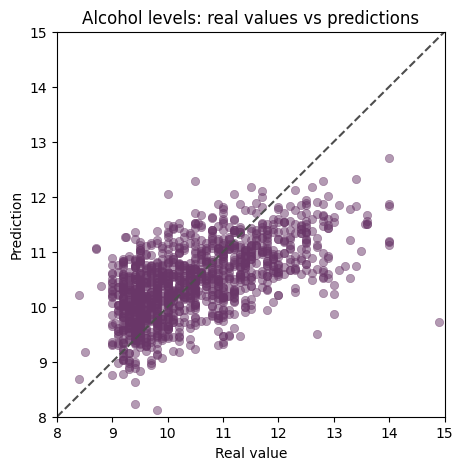

In [83]:
fig = plt.pyplot.figure(figsize=(5, 5))

ax = sns.scatterplot(x=y, y=predictions, edgecolor=None, color='#693668', alpha=0.5)
ax.set(
    title='Alcohol levels: real values vs predictions',
    ylabel='Prediction',
    xlabel='Real value',
    ylim=[8, 15],
    xlim=[8, 15],
)
ax.plot(ax.get_xlim(), ax.get_ylim(), ls="--", c=".3");

The Real value vs Predicted value plot shows that the model overestimates alcohol levels for wines with low levels of alcohol and understestimates for ones with high levels of alcohol.

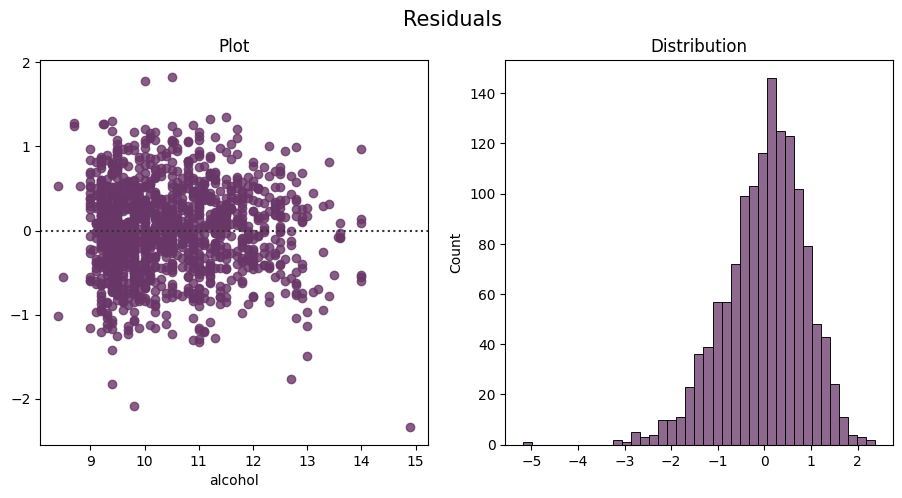

In [84]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Residuals', fontsize=15)

ax1 = sns.residplot(x=y, y=predictions, data=data, color='#693668', ax=axs[0])
ax1.set(title='Plot')
ax2 = sns.histplot(residuals, color='#693668', ax=axs[1])
ax2.set(title='Distribution');

Distribution of residuals is approximately normal, as we can see from the plots. The distribution is skewed to the left. 

### Model 2

For second model, we are going to select 4 features: chlorides, density, pH and quality.

In [85]:
x2 = data[['chlorides', 'density', 'pH', 'quality']]
x2.head()

,chlorides,density,pH,quality
0,0.076,0.9978,3.51,5
1,0.098,0.9968,3.20,5
2,0.092,0.9970,3.26,5
3,0.075,0.9980,3.16,6
5,0.075,0.9978,3.51,5


In [86]:
model2 = sm.OLS(y, x2)
res2 = model2.fit()
res2.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                alcohol   R-squared (uncentered):                   0.993
Model:                            OLS   Adj. R-squared (uncentered):              0.992
Method:                 Least Squares   F-statistic:                          4.490e+04
Date:                Tue, 23 Jan 2024   Prob (F-statistic):                        0.00
Time:                        22:45:07   Log-Likelihood:                         -1796.5
No. Observations:                1359   AIC:                                      3601.
Df Residuals:                    1355   BIC:                                      3622.
Df Model:                           4                                                  
Covariance Type:            nonrobust                                                  
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
chlorides     -2.1532      0.526     -4.097      0.000      -3.184      -1.122
density        1.7923      0.599      2.993      0.003       0.618       2.967
pH             1.5874      0.164      9.709      0.000       1.267       1.908
quality        0.6368      0.030     21.057      0.000       0.577       0.696
==============================================================================
Omnibus:                      127.088   Durbin-Watson:                   1.568
Prob(Omnibus):                  0.000   Jarque-Bera (JB):              177.662
Skew:                           0.730   Prob(JB):                     2.64e-39
Kurtosis:                       4.004   Cond. No.                         183.
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [87]:
predictions2 = res2.predict(x2)
predictions2.head()

0    10.380656
1     9.839391
2     9.947915
3    10.464384
5    10.382809
dtype: float64

In [88]:
residuals2 = predictions2 - y

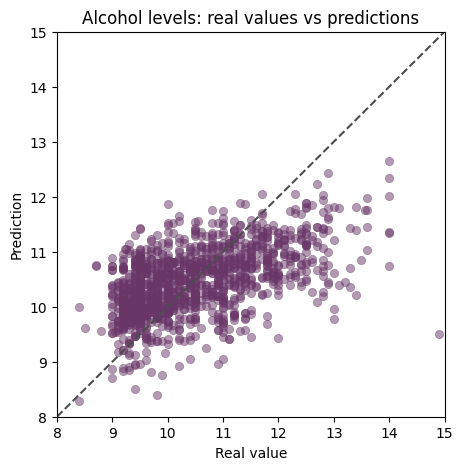

In [89]:
fig = plt.pyplot.figure(figsize=(5, 5))

ax = sns.scatterplot(x=y, y=predictions2, edgecolor=None, color='#693668', alpha=0.5)
ax.set(
    title='Alcohol levels: real values vs predictions',
    ylabel='Prediction',
    xlabel='Real value',
    ylim=[8, 15],
    xlim=[8, 15],
)
ax.plot(ax.get_xlim(), ax.get_ylim(), ls="--", c=".3");

The Real value vs Predicted value plot shows that the model overestimates alcohol levels for wines with low levels of alcohol and understestimates for ones with high levels of alcohol just like in the previous model.

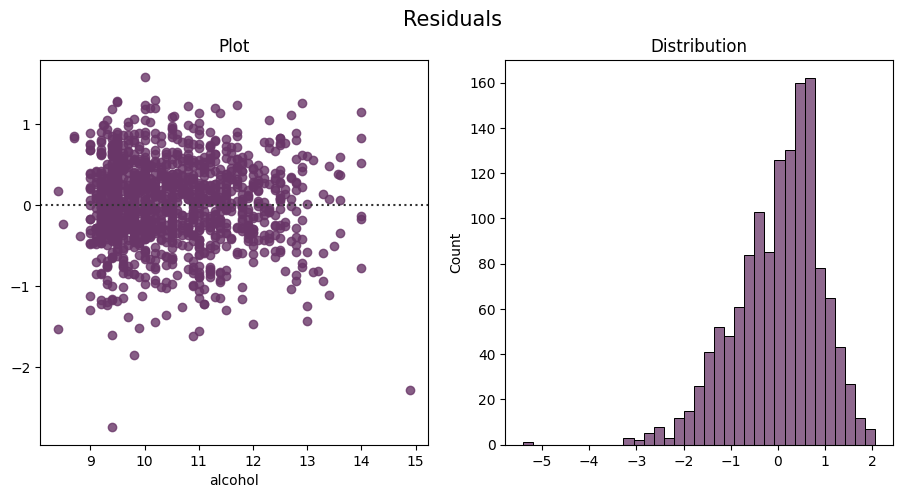

In [90]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Residuals', fontsize=15)

ax1 = sns.residplot(x=y, y=predictions2, data=data, color='#693668', ax=axs[0])
ax1.set(title='Plot')
ax2 = sns.histplot(residuals2, color='#693668', ax=axs[1])
ax2.set(title='Distribution');

Distribution of residuals is approximately normal, as we can see from the plots. The distribution is skewed to the left. 

### Model 3 - no outliers dataset

In [91]:
x = data_noout.drop('alcohol', axis=1)
x.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,6
5,7.4,0.66,0.00,1.8,0.075,13.0,40.0,0.9978,3.51,0.56,5


In [92]:
y = data_noout.alcohol
y.head()

0    9.4
1    9.8
2    9.8
3    9.8
5    9.4
Name: alcohol, dtype: float64

In [93]:
model = sm.OLS(y, x)
res = model.fit()
res.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                 OLS Regression Results                                
=======================================================================================
Dep. Variable:                alcohol   R-squared (uncentered):                   0.994
Model:                            OLS   Adj. R-squared (uncentered):              0.994
Method:                 Least Squares   F-statistic:                          1.611e+04
Date:                Tue, 23 Jan 2024   Prob (F-statistic):                        0.00
Time:                        22:45:07   Log-Likelihood:                         -1173.5
No. Observations:                1005   AIC:                                      2369.
Df Residuals:                     994   BIC:                                      2423.
Df Model:                          11                                                  
Covariance Type:            nonrobust                                                  
========================================================================================
                           coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------------
fixed acidity           -0.1057      0.030     -3.502      0.000      -0.165      -0.046
volatile acidity         0.2650      0.209      1.269      0.205      -0.145       0.675
citric acid              1.2599      0.232      5.422      0.000       0.804       1.716
residual sugar           0.3955      0.060      6.615      0.000       0.278       0.513
chlorides              -12.3742      1.804     -6.860      0.000     -15.914      -8.834
free sulfur dioxide      0.0088      0.004      2.343      0.019       0.001       0.016
total sulfur dioxide    -0.0093      0.001     -7.083      0.000      -0.012      -0.007
density                  5.1910      1.092      4.751      0.000       3.047       7.335
pH                       0.8549      0.276      3.093      0.002       0.313       1.397
sulphates                0.3830      0.250      1.529      0.127      -0.109       0.874
quality                  0.5143      0.040     12.966      0.000       0.437       0.592
==============================================================================
Omnibus:                       29.729   Durbin-Watson:                   1.638
Prob(Omnibus):                  0.000   Jarque-Bera (JB):               31.647
Skew:                           0.431   Prob(JB):                     1.34e-07
Kurtosis:                       3.120   Cond. No.                     3.94e+03
==============================================================================

Notes:
[1] R² is computed without centering (uncentered) since the model does not contain a constant.
[2] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[3] The condition number is large, 3.94e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

In [94]:
predictions = res.predict(x)
predictions.head()

0     9.962581
1     9.565865
2     9.613158
3    10.203102
5     9.886795
dtype: float64

In [95]:
residuals = predictions - y

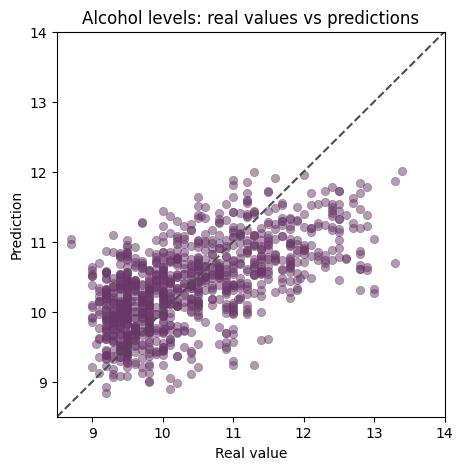

In [96]:
fig = plt.pyplot.figure(figsize=(5, 5))

ax = sns.scatterplot(x=y, y=predictions, edgecolor=None, color='#693668', alpha=0.5)
ax.set(
    title='Alcohol levels: real values vs predictions',
    ylabel='Prediction',
    xlabel='Real value',
    ylim=[8.5, 14],
    xlim=[8.5, 14],
)
ax.plot(ax.get_xlim(), ax.get_ylim(), ls="--", c=".3");

Without outliers, the model performs better and the predictred values are closer to real values compared to full dataset.

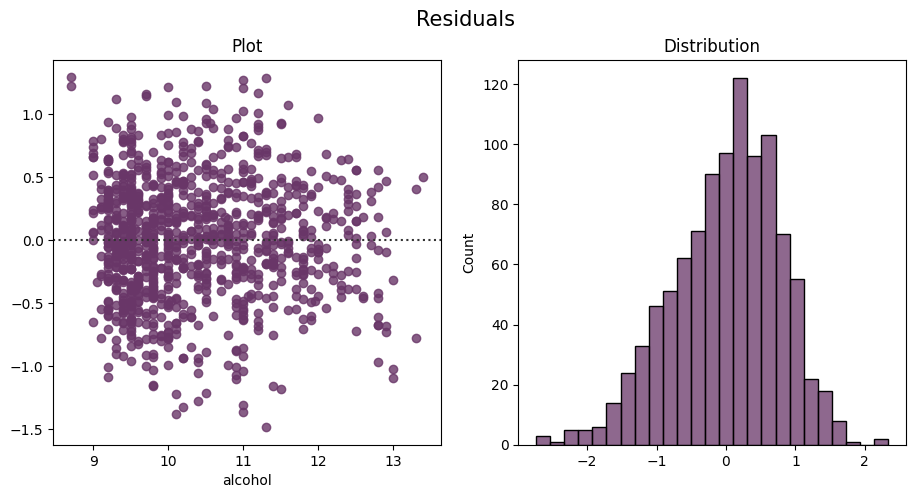

In [97]:
fig, axs = plt.pyplot.subplots(1, 2, figsize=(11, 5))
fig.suptitle('Residuals', fontsize=15)

ax1 = sns.residplot(x=y, y=predictions, data=data, color='#693668', ax=axs[0])
ax1.set(title='Plot')
ax2 = sns.histplot(residuals, color='#693668', ax=axs[1])
ax2.set(title='Distribution');

The residuals are smaller and the distribution of them is less skewed to the left compared to full dataset models.

### Conclusion

All three models testest had high *R<sup>2</sup>* values - around 0.99. All of the models tended to slightly overestimate alcohol levels for wines with low alcohol level and underestimate alcohol levels for wines with high alcohol level. Model 1 had AIC score of 3490, model 2 - 3601. Model 3 has the lowest AIC score - 2369, however it does not use all of the datasets values as the outliers were excluded in this dataset and it is unknown how it would perform on real data with outliers. Therefore, model 1 should be overall best from out three tested to predict alcohol content in real data.

# Summary

- Some of the features measured in the red wine, have high correlations: fixed acidity with citric acid and density - they positively correlated. Total sulfur dioxide and free sulfur dioxide are also positively correlated. pH is negatively correlated with fixed acidity and citric acid. Volatile acidity is negatively correlated with citric acid, and alcohol is negatively correlated with density.
- Volatile acidity does not seem to correlated with alcohol in any way. We can see a slight tendency for higher quality wines to have higher alcohol content and lower volatile acidity.
- Three hypothesies were tested and here are the results:
  - We can see that there is no statistically significant difference between chloride levels between different quality wines, except for quality 7 and quality 5 wines.
  - The alcohol levels in quality 6 wines tends to be higher compared to quality 5 wines.
  - There is statistically significant difference between quality 4 and 7 wine's pH levels. The pH levels in quality 7 wines tend to slightly higher.
- Logistic regression models were used to classify wines into different qualities:
  - Models to clasify wines to premium (7 or 8 quality) and premium had around 90% accuracy and best performed when all of the features were used.
  - Models to classify wines into three different qualities: low (3 and 4 quality), medium (5 and 6) and high (7 and 8), also performed better when all of the features were used instead of just 4, but testing results were close. The model also failed to clasify wines into low and high qualities and tended to clasify most of wines as medium quality.
- Linear regression model was used to predict alcohol levels in the wine. 3 models were created – model 1 used all features, model 2 just 4 and model 3 used all features and data without outliers. The best at predicting was model 3, as it had lowest AIC score and residuals, however it is unknown how it would perform on real data with outliers. Therefore, model 1 should be overall best from all three tested.

# Suggestions for improvement

- Try more different feature combinations for models to find out if there are any which perform better without all of the features. 
- Investigate sulphate feature more as there is not much information about it online. 
- Make a training/testing sets for linear model. 
- Better visuals for confusion matrixes and models.
- Make more scatterplots for features (how they depend on one another).
- Improve model for classifying wines into three cathegories - low, medium and high as it tends to classify wines only as medium quality.